In [5]:
import os
import glob
import zipfile
from google.colab import files

In [2]:
import pandas as pd
import io

In [3]:
import sqlite3

In [4]:
#upload your downloaded zip file
uploaded=files.upload()

Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_customers_dataset.csv to olist_customers_dataset.csv


In [6]:
#load all uploaded csv files
dataframes={}
for filename, content in uploaded.items():
  if filename.lower().endswith(".csv"):
    df=pd.read_csv(io.BytesIO(content))
    dataframes[filename]=df
    print(f"\nFile: {filename}")
    print("Rows:",df.shape[0])
    print("column:",df.shape[1])



File: olist_orders_dataset.csv
Rows: 99441
column: 8

File: olist_products_dataset.csv
Rows: 32951
column: 9

File: olist_sellers_dataset.csv
Rows: 3095
column: 4

File: product_category_name_translation.csv
Rows: 71
column: 2

File: olist_order_reviews_dataset.csv
Rows: 99224
column: 7

File: olist_order_payments_dataset.csv
Rows: 103886
column: 5

File: olist_order_items_dataset.csv
Rows: 112650
column: 7

File: olist_geolocation_dataset.csv
Rows: 1000163
column: 5

File: olist_customers_dataset.csv
Rows: 99441
column: 5


In [7]:
#inspect the structure of all 9 tables
for filename, df in dataframes.items():
  print("\n"+"="*65)
  print("TABLE:",filename)
  print("shape:",df.shape)
  print("missing value",df.isnull().sum().sum())
  print("-"*65)
  display(df.head(3))


TABLE: olist_orders_dataset.csv
shape: (99441, 8)
missing value 4908
-----------------------------------------------------------------


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



TABLE: olist_products_dataset.csv
shape: (32951, 9)
missing value 2448
-----------------------------------------------------------------


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0



TABLE: olist_sellers_dataset.csv
shape: (3095, 4)
missing value 0
-----------------------------------------------------------------


...

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87



TABLE: olist_geolocation_dataset.csv
shape: (1000163, 5)
missing value 0
-----------------------------------------------------------------


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP



TABLE: olist_customers_dataset.csv
shape: (99441, 5)
missing value 0
-----------------------------------------------------------------


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


In [8]:
for filename, df in dataframes.items():
  print("\n"+"="*60)
  print("Table:",filename)
  missing=df.isnull().sum()
  missing=missing[missing>0].sort_values(ascending=False)



Table: olist_orders_dataset.csv

Table: olist_products_dataset.csv

Table: olist_sellers_dataset.csv

Table: product_category_name_translation.csv

Table: olist_order_reviews_dataset.csv

Table: olist_order_payments_dataset.csv

Table: olist_order_items_dataset.csv

Table: olist_geolocation_dataset.csv

Table: olist_customers_dataset.csv


In [9]:
print("\n missing values by column")
if missing.empty:
  print("no missing value")
else:
  print(missing.to_string())
#Exact duplicate rows
print("\n exact duplicate row",df.duplicated().sum())
#duplicate primary/ business identifiers were applicable
if "order_id" in df.columns:
  print("unique order id",df['order_id'].nunique())
if "review_score" in df.columns:
  print("Review score distribution")
  print(df['review_score'].value_counts(dropna=False).sort_index())



 missing values by column
no missing value

 exact duplicate row 0


In [10]:
#create a database file
db_path='/content/ecommerce.db'
conn=sqlite3.connect(db_path)

#load all csv dataframes into sqllite tables
for filename, df in dataframes.items():
  table_name=os.path.splitext(filename)[0]
  df.to_sql(name=table_name,con=conn, if_exists="replace", index=False, chunksize=10000)
  print(f"loaded: {table_name}| Rows: {len(df)}")
print("\n Database created successfully")
print("database file:",db_path)

loaded: olist_orders_dataset| Rows: 99441
loaded: olist_products_dataset| Rows: 32951
loaded: olist_sellers_dataset| Rows: 3095
loaded: product_category_name_translation| Rows: 71
loaded: olist_order_reviews_dataset| Rows: 99224
loaded: olist_order_payments_dataset| Rows: 103886
loaded: olist_order_items_dataset| Rows: 112650
loaded: olist_geolocation_dataset| Rows: 1000163
loaded: olist_customers_dataset| Rows: 99441

 Database created successfully
database file: /content/ecommerce.db


In [11]:
#verify table and row_counts using sql
query="""
SELECT name AS table_name
FROM sqlite_master WHERE type='table'
ORDER BY name;
"""
tables=pd.read_sql_query(query,conn)
display(tables)

#check row counts
for table in tables['table_name']:
  result=pd.read_sql_query(f'SELECT COUNT(*) AS total_rows FROM "{table}"',conn)
  print(f"{table}:{result.iloc[0,0]:,}rows")

,table_name
0,olist_customers_dataset
1,olist_geolocation_dataset
2,olist_order_items_dataset
3,olist_order_payments_dataset
4,olist_order_reviews_dataset
5,olist_orders_dataset
6,olist_products_dataset
7,olist_sellers_dataset
8,product_category_name_translation


olist_customers_dataset:99,441rows
olist_geolocation_dataset:1,000,163rows
olist_order_items_dataset:112,650rows
olist_order_payments_dataset:103,886rows
olist_order_reviews_dataset:99,224rows
olist_orders_dataset:99,441rows
olist_products_dataset:32,951rows
olist_sellers_dataset:3,095rows
product_category_name_translation:71rows


In [13]:

query = """
WITH monthly_orders AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(*) AS total_orders
    FROM olist_orders_dataset
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
),
monthly_payments AS (
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS month,
        SUM(p.payment_value) AS total_payment_value
    FROM olist_orders_dataset AS o
    JOIN olist_order_payments_dataset AS p
        ON o.order_id = p.order_id
    GROUP BY strftime('%Y-%m', o.order_purchase_timestamp)
)
SELECT
    mo.month,
    mo.total_orders,
    ROUND(mp.total_payment_value, 2) AS total_payment_value
FROM monthly_orders AS mo
LEFT JOIN monthly_payments AS mp
    ON mo.month = mp.month
WHERE mo.month IS NOT NULL
ORDER BY mo.month;
"""

monthly_sales = pd.read_sql_query(query, conn)
display(monthly_sales)


,month,total_orders,total_payment_value
0,2016-09,4,252.24
1,2016-10,324,59090.48
2,2016-12,1,19.62
3,2017-01,800,138488.04
4,2017-02,1780,291908.01
5,2017-03,2682,449863.60
6,2017-04,2404,417788.03
7,2017-05,3700,592918.82
8,2017-06,3245,511276.38
9,2017-07,4026,592382.92


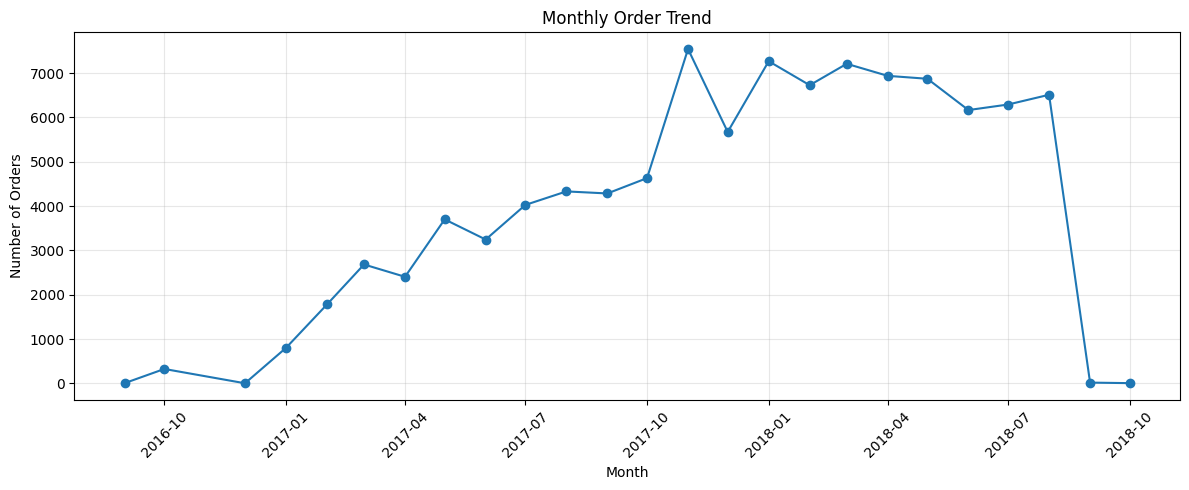

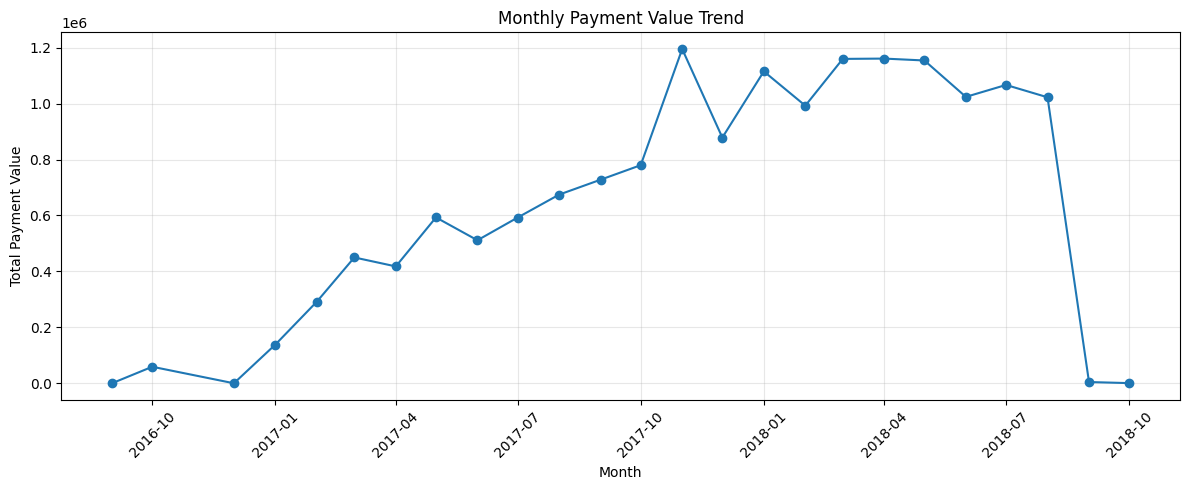

In [14]:

import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for visualization
monthly_sales["month"] = pd.to_datetime(
    monthly_sales["month"],
    format="%Y-%m"
)

# Chart 1: Monthly orders
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["total_orders"],
    marker="o"
)
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Monthly payment value
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["total_payment_value"],
    marker="o"
)
plt.title("Monthly Payment Value Trend")
plt.xlabel("Month")
plt.ylabel("Total Payment Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

query = """
SELECT
    COALESCE(t.product_category_name_english,
             p.product_category_name,
             'unknown') AS category,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(*) AS items_sold,
    ROUND(SUM(oi.price), 2) AS product_sales
FROM olist_order_items_dataset AS oi
JOIN olist_products_dataset AS p
    ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation AS t
    ON p.product_category_name = t.product_category_name
GROUP BY category
ORDER BY product_sales DESC
LIMIT 10;
"""

top_categories = pd.read_sql_query(query, conn)
display(top_categories)


,category,total_orders,items_sold,product_sales
0,health_beauty,8836,9670,1258681.34
1,watches_gifts,5624,5991,1205005.68
2,bed_bath_table,9417,11115,1036988.68
3,sports_leisure,7720,8641,988048.97
4,computers_accessories,6689,7827,911954.32
5,furniture_decor,6449,8334,729762.49
6,cool_stuff,3632,3796,635290.85
7,housewares,5884,6964,632248.66
8,auto,3897,4235,592720.11
9,garden_tools,3518,4347,485256.46


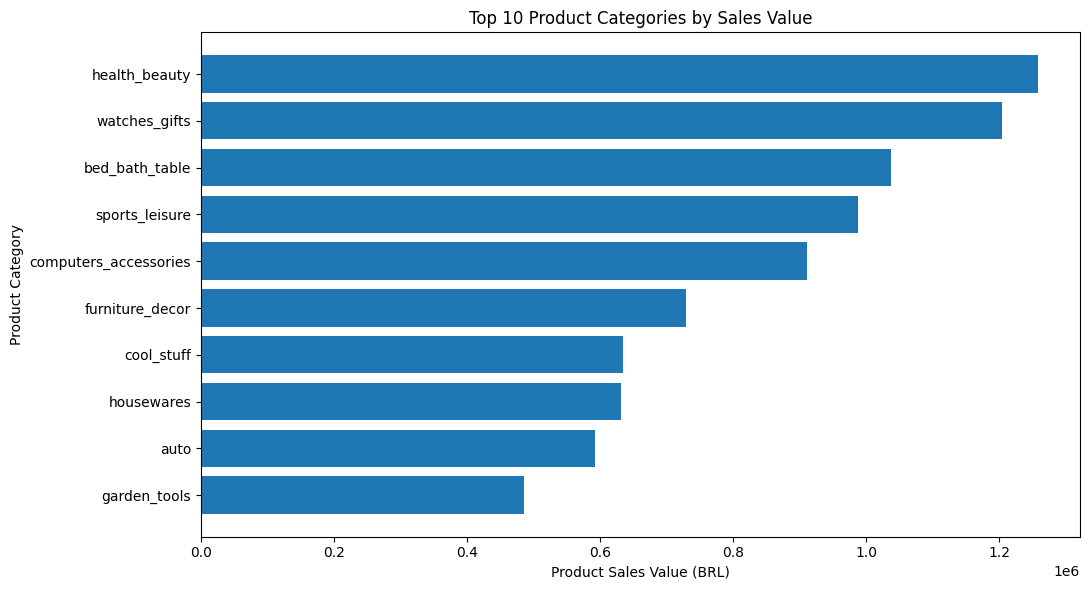

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.barh(
    top_categories["category"][::-1],
    top_categories["product_sales"][::-1]
)

plt.title("Top 10 Product Categories by Sales Value")
plt.xlabel("Product Sales Value (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [17]:

query = """
WITH delivery_analysis AS (
    SELECT
        order_id,
        order_status,
        order_purchase_timestamp,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        CASE
            WHEN order_delivered_customer_date IS NULL
                THEN NULL
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
                THEN 1
            ELSE 0
        END AS is_late,
        CASE
            WHEN order_delivered_customer_date IS NOT NULL
            THEN (
                julianday(order_delivered_customer_date) -
                julianday(order_purchase_timestamp)
            )
            ELSE NULL
        END AS delivery_days
    FROM olist_orders_dataset
)
SELECT
    d.order_status,
    COUNT(*) AS total_orders,
    SUM(d.is_late) AS late_delivered_orders,
    ROUND(AVG(d.delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(r.review_score), 2) AS avg_review_score
FROM delivery_analysis d
LEFT JOIN olist_order_reviews_dataset r
    ON d.order_id = r.order_id
GROUP BY d.order_status
ORDER BY total_orders DESC;
"""

delivery_analysis = pd.read_sql_query(query, conn)
display(delivery_analysis)


,order_status,total_orders,late_delivered_orders,avg_delivery_days,avg_review_score
0,delivered,97007,7865.0,12.56,4.16
1,shipped,1118,NaN,NaN,2.01
2,canceled,629,1.0,20.36,1.81
3,unavailable,611,NaN,NaN,1.53
4,invoiced,318,NaN,NaN,1.66
5,processing,302,NaN,NaN,1.28
6,created,5,NaN,NaN,2.33
7,approved,2,NaN,NaN,2.50


In [18]:

query = """
SELECT
    COUNT(*) AS delivered_orders,

    SUM(
        CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 1 ELSE 0
        END
    ) AS late_orders,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN order_delivered_customer_date >
                     order_estimated_delivery_date
                THEN 1 ELSE 0
            END
        ) / COUNT(*), 2
    ) AS late_delivery_percentage,

    ROUND(
        AVG(
            julianday(order_delivered_customer_date) -
            julianday(order_purchase_timestamp)
        ), 2
    ) AS avg_delivery_days

FROM olist_orders_dataset
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL;
"""

delivery_metrics = pd.read_sql_query(query, conn)
display(delivery_metrics)


,delivered_orders,late_orders,late_delivery_percentage,avg_delivery_days
0,96470,7826,8.11,12.56


In [19]:

query = """
WITH delivery_status AS (
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 'Late'
            ELSE 'On Time'
        END AS delivery_group
    FROM olist_orders_dataset
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT
    d.delivery_group,
    COUNT(DISTINCT d.order_id) AS total_orders,
    ROUND(AVG(r.review_score), 2) AS avg_review_score,
    COUNT(r.review_score) AS orders_with_reviews
FROM delivery_status d
LEFT JOIN olist_order_reviews_dataset r
    ON d.order_id = r.order_id
GROUP BY d.delivery_group
ORDER BY d.delivery_group;
"""

review_comparison = pd.read_sql_query(query, conn)
display(review_comparison)


,delivery_group,total_orders,avg_review_score,orders_with_reviews
0,Late,7826,2.57,7700
1,On Time,88644,4.29,88653


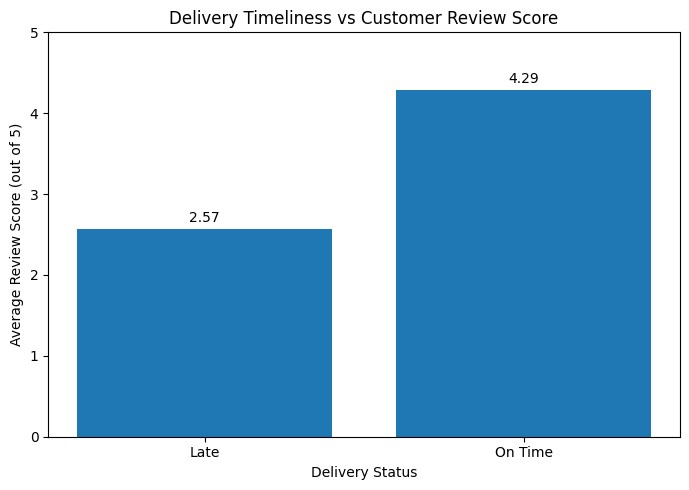

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    review_comparison["delivery_group"],
    review_comparison["avg_review_score"]
)

plt.title("Delivery Timeliness vs Customer Review Score")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)

for i, score in enumerate(review_comparison["avg_review_score"]):
    plt.text(i, score + 0.08, f"{score:.2f}", ha="center")

plt.tight_layout()
plt.show()
